# Lab 9: Gyroscope parameters

Fayozbek Yusupov, ID 240061

The robot only logs, everything is computed here. I chose Option A: the robot turns in place, the right wheel (M3) gets `u` and the left wheel (M4) gets `-u`.

The program runs 2 min of warm-up without logging, 3 min at rest (`static`), 36 s of `sin` and 36 s of `rect` with the period 4 s and the amplitude 30 → 60 → 150 % (12 s each, clipped to ±100 %), and 3 s at rest at the end (`rest`).

On the robot I ran `lab9_gyro.js`, because the README asks for `readRawData()` and the TRIK Studio blocks cannot read it: the block variable `gyroscope` is `read()`. `lab9_gyro.qrs` is the same sequence in blocks (it logs `gyroscope[2]` and `gyroscope[3]`), I checked it in the 2D simulator.

Columns of `lab9_gyro.csv`: `t_us` = `read()[3]`, `gz_cal` = `read()[2]` in mdeg/s, `encL` = E4, `encR` = E3, `gz_raw` = `readRawData()[2]`, `u` = motor power, `t_ms` = program clock, `phase`.

Upload `lab9_gyro.csv` in the next cell.

In [1]:
from google.colab import files      # file work module
import numpy as np                  # array work module
import pandas as pd                 # table work module
import matplotlib.pyplot as plt     # data visualization

uploaded = files.upload()           # select lab9_gyro.csv

## Data and time

In [2]:
log = pd.read_csv('lab9_gyro.csv')

# how long is one unit of the gyroscope time stamp: compare it with the program clock t_ms
unit = np.polyfit(log.t_us - log.t_us[0], log.t_ms - log.t_ms[0], 1)[0]
print(f'one unit of t_us = {unit:.4f} ms')

repeated = (log.t_us.diff() == 0).sum()
log = log[log.t_us.diff() != 0].reset_index(drop=True)   # the same gyro sample read twice: keep one
print(f'{repeated} repeated gyro samples removed')

log['t'] = (log.t_us - log.t_us[0]) * 0.256 / 1000        # time of the gyro sample, s
log['gz'] = log.gz_cal / 1000                             # deg/s

static = log[log.phase == 'static'].copy()
turn = log[log.phase != 'static'].copy()                  # sin, rect and 3 s of rest
static['t'] -= static.t.iloc[0]
turn['t'] -= turn.t.iloc[0]

for name in ['static', 'sin', 'rect', 'rest']:
    part = log[log.phase == name]
    print(f'{name:7s} {len(part):5d} samples, {part.t.iloc[-1] - part.t.iloc[0]:6.1f} s, one sample every {1000 * part.t.diff().mean():.0f} ms')

one unit of t_us = 0.2560 ms
10 repeated gyro samples removed
static   3890 samples,  180.0 s, one sample every 46 ms
sin       551 samples,   36.1 s, one sample every 66 ms
rect      553 samples,   36.0 s, one sample every 65 ms
rest       65 samples,    3.0 s, one sample every 46 ms


The README says `t_us` is in µs, but against the program clock one unit is 0.256 ms, so the time of a sample is `t_us` · 0.256 ms.

The pause in the loop is 10 ms, but one pass takes about 46 ms at rest and 65 ms when the motors are driven: every pass reads the gyroscope twice (`read` and `readRawData`) and both encoders, and these reads take the other 36 ms (in Lab 7 one pass of the block program was also about 45 ms). So the log has about 22 samples per second at rest and 15 in the rotation instead of 100, and all integrals below use the real time stamps.

## 1. Offset $b_0$

The mean of the gyro when the robot does not rotate. The baseline of the README is the mean of the first 30 s.

b0 = 1.053 deg/s, standard error 0.003 deg/s, N = 646
first  1 s: b0 = 1.026 deg/s
first  2 s: b0 = 1.008 deg/s
first  5 s: b0 = 1.028 deg/s
first 10 s: b0 = 1.065 deg/s
first 20 s: b0 = 1.068 deg/s
first 30 s: b0 = 1.053 deg/s


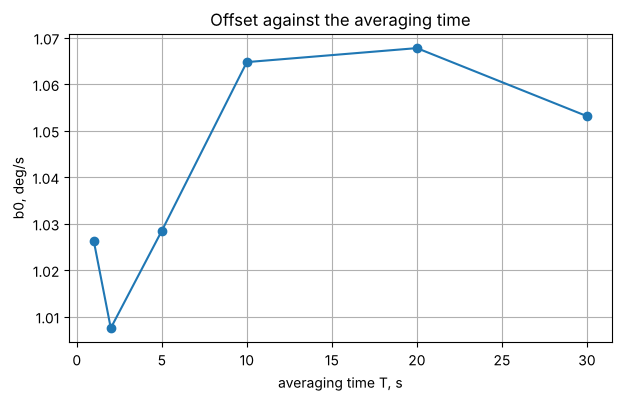

In [3]:
def integrate(w, t):
    # trapezoid rule with the real time stamps
    w = np.array(w); t = np.array(t)
    return np.concatenate([[0], np.cumsum((w[1:] + w[:-1]) / 2 * np.diff(t))])

first30 = static[static.t < 30]
b0 = first30.gz.mean()
se = first30.gz.std() / np.sqrt(len(first30))
print(f'b0 = {b0:.3f} deg/s, standard error {se:.3f} deg/s, N = {len(first30)}')

T_list = [1, 2, 5, 10, 20, 30]
b0_T = [static.gz[static.t < T].mean() for T in T_list]
for T, b in zip(T_list, b0_T):
    print(f'first {T:2d} s: b0 = {b:.3f} deg/s')

plt.figure(figsize=(7, 4))
plt.plot(T_list, b0_T, 'o-')
plt.xlabel('averaging time T, s'); plt.ylabel('b0, deg/s'); plt.grid(True)
plt.title('Offset against the averaging time')
plt.show()

$b_0$ = 1.053 ± 0.003 deg/s. On the plot $b_0$ still moves by 0.02-0.04 deg/s between 1, 2, 5 and 10 s and stays within 0.015 deg/s from 10 s on (1.065, 1.068, 1.053), so about 10 s is enough for a calibration.

My calibration method: `calibrate_gyro(log)` takes a log where the robot stands still and returns the median of its first 10 s. The median and not the mean, so that one bumped sample cannot shift the result; 10 s because the $b_0(T)$ curve is flat from there.

In [4]:
def calibrate_gyro(log, T=10):
    # log: gyro log while the robot stands still; returns b0 in deg/s
    part = log[log.t - log.t.iloc[0] < T]      # the first T seconds of this log
    return np.median(part.gz)                  # median: one bumped sample does not move it

b0_mine = calibrate_gyro(static)
print(f'my b0 from the first 10 s of the static log = {b0_mine:.3f} deg/s')

after = static[static.t >= 10]                 # what is left after these 10 s
left = integrate(after.gz - b0_mine, after.t)
for T in [60, 120, 170]:
    i = np.searchsorted(after.t - 10, T) - 1
    print(f'{T:3d} s after the calibration the heading error is {left[i]:.1f} deg')

my b0 from the first 10 s of the static log = 1.058 deg/s


 60 s after the calibration the heading error is -1.8 deg
120 s after the calibration the heading error is -5.1 deg
170 s after the calibration the heading error is -10.0 deg


My $b_0$ from the first 10 s is 1.058 deg/s. After this calibration the heading error at rest is -1.8° in 1 min, -5.1° in 2 min and -10.0° in 170 s (the rest of my static log), because the offset itself goes down during the log (section 2). So the calibration has to be done right before a run.

## 2. Bias drift $d$

How the offset changes during the 3 minutes at rest and what it does to the heading.

30-s window means, deg/s: [1.053 1.012 1.038 0.993 0.97  0.951]
d = -0.039 deg/s per min
(a) heading drift of the raw rate: 60.2 deg/min, b0 * 60 = 63.2 deg/min
(b) heading error after 1 min with b0 subtracted: -1.3 deg
(b) heading error after 2 min with b0 subtracted: -3.5 deg
(b) heading error after 3 min with b0 subtracted: -9.1 deg


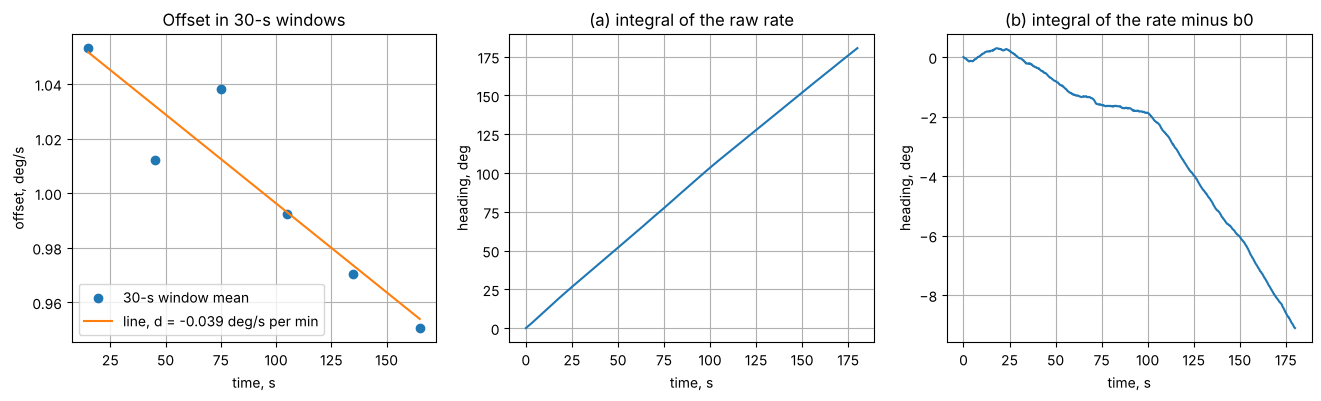

In [5]:
centres, means = [], []
for a in range(0, 180, 30):                          # 30-s windows
    w = static[(static.t >= a) & (static.t < a + 30)]
    centres.append(a + 15); means.append(w.gz.mean())
line = np.polyfit(centres, means, 1)
d = line[0]                                          # deg/s per s
print('30-s window means, deg/s:', np.round(means, 3))
print(f'd = {d * 60:.3f} deg/s per min')

theta_raw = integrate(static.gz, static.t)           # (a) raw rate
theta_cor = integrate(static.gz - b0, static.t)      # (b) rate minus b0
slope = np.polyfit(static.t, theta_raw, 1)[0] * 60
print(f'(a) heading drift of the raw rate: {slope:.1f} deg/min, b0 * 60 = {b0 * 60:.1f} deg/min')
for T in [60, 120, 180]:
    i = np.searchsorted(static.t, T) - 1
    print(f'(b) heading error after {T // 60} min with b0 subtracted: {theta_cor[i]:.1f} deg')

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
axs[0].plot(centres, means, 'o', label='30-s window mean')
axs[0].plot(centres, np.polyval(line, centres), label=f'line, d = {d * 60:.3f} deg/s per min')
axs[0].set_xlabel('time, s'); axs[0].set_ylabel('offset, deg/s'); axs[0].set_title('Offset in 30-s windows')
axs[1].plot(static.t, theta_raw)
axs[1].set_xlabel('time, s'); axs[1].set_ylabel('heading, deg'); axs[1].set_title('(a) integral of the raw rate')
axs[2].plot(static.t, theta_cor)
axs[2].set_xlabel('time, s'); axs[2].set_ylabel('heading, deg'); axs[2].set_title('(b) integral of the rate minus b0')
axs[0].legend()
for ax in axs: ax.grid(True)
plt.show()

The window means go down from 1.053 to 0.951 deg/s, the line gives $d$ = -0.039 deg/s per min.

(a) The integral of the raw rate grows almost linearly, 60.2 deg/min. $b_0 \cdot 60$ = 63.2 deg/min is a bit more, because $b_0$ is the offset of the first 30 s and later the offset is smaller.

(b) With $b_0$ subtracted the heading error is -1.3° after 1 min, -3.5° after 2 min and -9.1° after 3 min. It grows faster and faster, because the difference between the real offset and $b_0$ becomes bigger with time.

## Rotation run: gyro angle and encoder angle

$\theta_{gyro}$ is the integral of `gz` minus $b_0$. $\theta_{enc} = \frac{r}{L}(\varphi_R - \varphi_L)$ with r = 3.75 cm and L = 19.4 cm, the same values as in Lab 7. The rate from the encoders is the slope of $\theta_{enc}$ over 5 samples. The grey lines are the amplitude steps every 12 s.

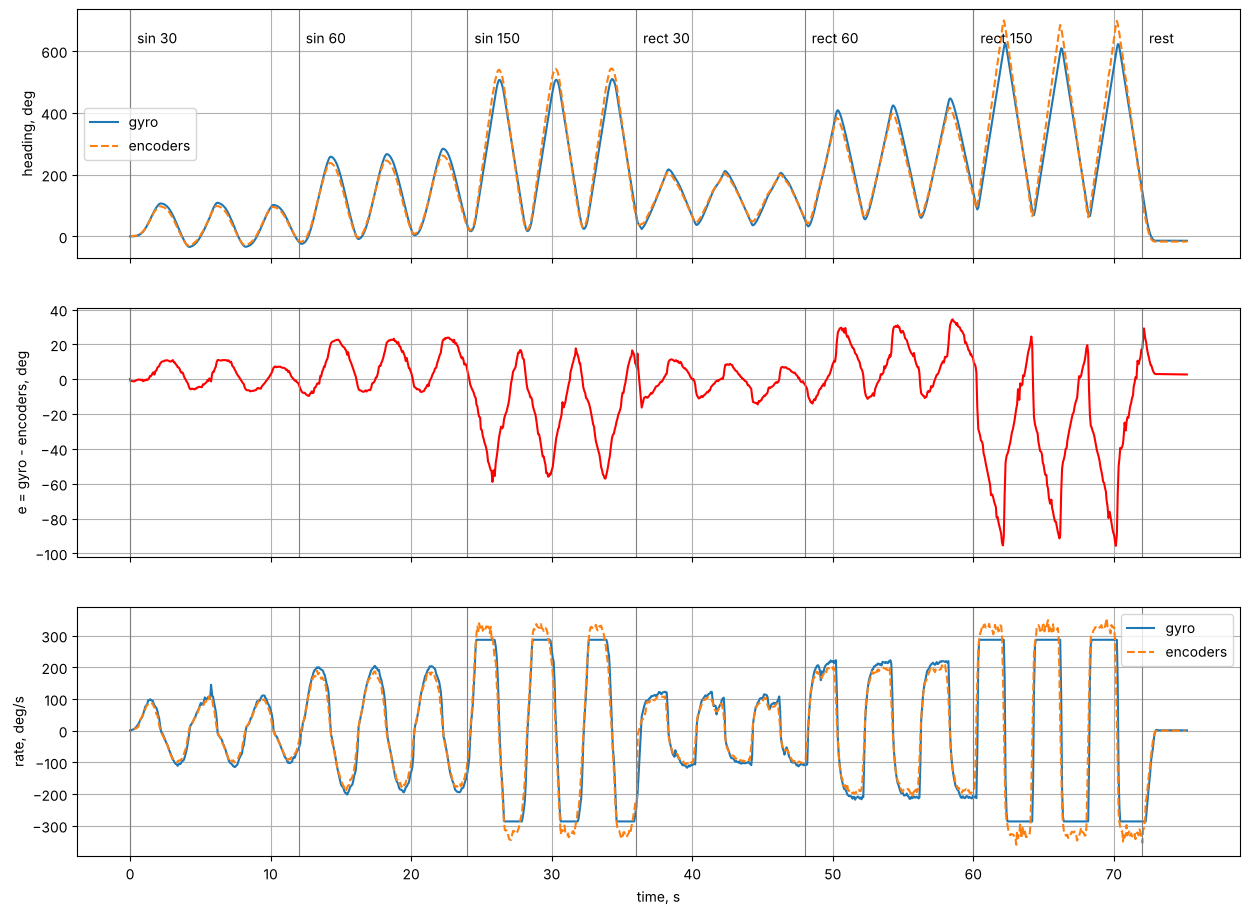

at the end: gyro -14.1 deg, encoders -16.8 deg, e = 2.7 deg
largest |e| during the run: 96 deg


In [6]:
r, L = 3.75, 19.4                                    # cm, wheel radius and track from Lab 5

theta_gyro = integrate(turn.gz - b0, turn.t)         # deg
enc = (turn.encR - turn.encR.iloc[0]) - (turn.encL - turn.encL.iloc[0])
theta_enc = r / L * enc.values                       # deg, the encoders are in degrees
e = theta_gyro - theta_enc

# rate from the encoders: slope of theta_enc over 5 samples
tt = turn.t.values
w_enc = np.full(len(tt), np.nan)
w_enc[2:-2] = (theta_enc[4:] - theta_enc[:-4]) / (tt[4:] - tt[:-4])

names = ['sin 30', 'sin 60', 'sin 150', 'rect 30', 'rect 60', 'rect 150', 'rest']
fig, axs = plt.subplots(3, 1, figsize=(15, 11), sharex=True)
axs[0].plot(tt, theta_gyro, label='gyro')
axs[0].plot(tt, theta_enc, '--', label='encoders')
axs[0].set_ylabel('heading, deg'); axs[0].legend()
axs[1].plot(tt, e, 'r')
axs[1].set_ylabel('e = gyro - encoders, deg')
axs[2].plot(tt, turn.gz, label='gyro')
axs[2].plot(tt, w_enc, '--', label='encoders')
axs[2].set_ylabel('rate, deg/s'); axs[2].set_xlabel('time, s'); axs[2].legend()
for ax in axs:
    ax.grid(True)
    for i in range(7):
        ax.axvline(12 * i, color='gray', lw=0.8)
for i, name in enumerate(names):
    axs[0].text(12 * i + 0.5, axs[0].get_ylim()[1] * 0.85, name)
plt.show()

print(f'at the end: gyro {theta_gyro[-1]:.1f} deg, encoders {theta_enc[-1]:.1f} deg, e = {e[-1]:.1f} deg')
print(f'largest |e| during the run: {np.abs(e).max():.0f} deg')

The two angles have the same shape and size, so the gyro is positive counter-clockwise like the encoders, and the encoders are in degrees and not in ticks.

Where $e(t)$ grows:

- At 30 and 60 % $e$ rises in every counter-clockwise swing and falls back in the clockwise one, by about 9 % of the turned angle. This is the scale factor (section 6).
- At 150 % the gyro stays at its limit while the encoders show a higher rate, so in every fast swing the gyro loses up to 60° (sin) and 95° (rect) and gets it back on the way back. This is saturation (section 3).
- I do not see separate jumps from wheel slip: on the sharp `rect` steps the slopes of the swings are the same as on the smooth `sin` (section 6).
- The offset error is hidden under these swings here; it is checked at the end of the notebook.

At the end the gyro shows -14.1° and the encoders -16.8°.

## 3. Measurement range $\omega_{max}$

At the amplitude 150 % the motors get ±100 %, these are the fastest turns.

limits: +286.7 and -286.4 deg/s (raw 32764 and -32736)
292 of 1169 samples are at the limit
encoder rate in these samples: up to +354 and -360 deg/s


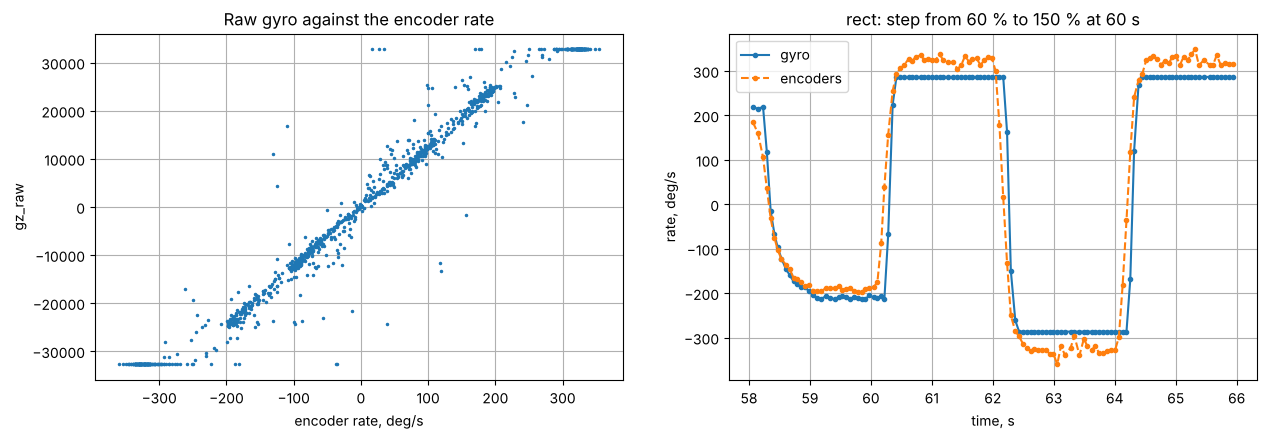

In [7]:
sat = (turn.gz_raw.abs() > 32700).values             # samples at the limit
print(f'limits: +{turn.gz.max():.1f} and {turn.gz.min():.1f} deg/s (raw {turn.gz_raw.max()} and {turn.gz_raw.min()})')
print(f'{sat.sum()} of {len(turn)} samples are at the limit')
print(f'encoder rate in these samples: up to +{np.nanmax(w_enc[sat]):.0f} and {np.nanmin(w_enc[sat]):.0f} deg/s')

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
axs[0].plot(w_enc, turn.gz_raw, '.', ms=3)
axs[0].set_xlabel('encoder rate, deg/s'); axs[0].set_ylabel('gz_raw'); axs[0].set_title('Raw gyro against the encoder rate')
zoom = (tt > 58) & (tt < 66)
axs[1].plot(tt[zoom], turn.gz[zoom], '.-', label='gyro')
axs[1].plot(tt[zoom], w_enc[zoom], '.--', label='encoders')
axs[1].set_xlabel('time, s'); axs[1].set_ylabel('rate, deg/s'); axs[1].set_title('rect: step from 60 % to 150 % at 60 s'); axs[1].legend()
for ax in axs: ax.grid(True)
plt.show()

The gyro stops at +286.7 and -286.4 deg/s (raw 32764 and -32736, close to the ends of a 16-bit number), while the encoders show up to +354 and -360 deg/s. On both plots this is the flat top. 292 of the 1169 samples of the rotation run are at the limit, so the robot reaches the limit by itself at ±100 % power and a spin by hand is not needed.

## 4. Resolution $\Delta$

The smallest change of the output at rest.

In [8]:
big = ~sat & (turn.gz_raw.abs() > 50).values                  # rotation, not at the limit
k_raw = np.median(turn.gz_cal[big] / turn.gz_raw[big]) / 1000  # deg/s per raw unit, the plot is in section 6
raw_values = np.sort(static.gz_raw.unique())
step = np.diff(raw_values).min()
print(f'{len(raw_values)} different raw values at rest, from {raw_values[0]} to {raw_values[-1]}, smallest step {step}')
print(f'delta = {step} * {k_raw:.5f} = {step * k_raw:.5f} deg/s')
print('steps of gz_cal at rest, mdeg/s:', np.unique(np.diff(np.sort(static.gz_cal.unique())))[:2])

60 different raw values at rest, from 86 to 145, smallest step 1
delta = 1 * 0.00875 = 0.00875 deg/s
steps of gz_cal at rest, mdeg/s: [8 9]


At rest the raw output takes 60 different values from 86 to 145 and the smallest step is 1 unit, so $\Delta$ = 1 unit = 0.00875 deg/s (the factor is from section 6). `gz_cal` changes in steps of 8 or 9 mdeg/s, because it is 8.75 · raw written as a whole number.

## 5. Noise $\sigma$

The 3-min static log with $b_0$ subtracted.

sigma = 0.079 deg/s, mean of the noise -0.050 deg/s
12 of 3890 samples are more than 3 sigma from the mean (0.31 %, a Gaussian gives 0.27 %)
smallest -0.33, largest 0.21 deg/s


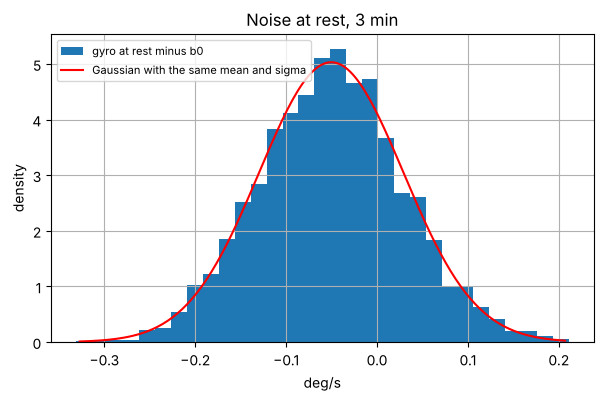

In [9]:
noise = static.gz - b0
sigma = noise.std()
far = (np.abs(noise - noise.mean()) > 3 * sigma).sum()
print(f'sigma = {sigma:.3f} deg/s, mean of the noise {noise.mean():.3f} deg/s')
print(f'{far} of {len(noise)} samples are more than 3 sigma from the mean ({100 * far / len(noise):.2f} %, a Gaussian gives 0.27 %)')
print(f'smallest {noise.min():.2f}, largest {noise.max():.2f} deg/s')

x = np.linspace(noise.min(), noise.max(), 200)
gauss = np.exp(-(x - noise.mean()) ** 2 / (2 * sigma ** 2)) / (sigma * np.sqrt(2 * np.pi))
plt.figure(figsize=(7, 4))
bins = np.arange(noise.min() - step * k_raw / 2, noise.max() + 2 * step * k_raw, 2 * step * k_raw)   # 2 raw units wide
plt.hist(noise, bins=bins, density=True, label='gyro at rest minus b0')
plt.plot(x, gauss, 'r', label='Gaussian with the same mean and sigma')
plt.xlabel('deg/s'); plt.ylabel('density'); plt.grid(True); plt.legend(loc='upper left', fontsize=8)
plt.title('Noise at rest, 3 min')
plt.show()

$\sigma$ = 0.079 deg/s. The histogram follows the Gaussian curve: 12 of 3890 samples (0.31 %) are farther than 3$\sigma$ from the mean, a Gaussian gives 0.27 %, and there are no spikes (all samples are between -0.33 and +0.21 deg/s). The mean is -0.050 deg/s and not 0, because $b_0$ is the offset of the first 30 s and later the offset is lower. This $\sigma$ is for my sample rate, about 22 samples per second.

## 6. Scale factor $s$

One swing is the time while the motor command keeps its sign, so the robot turns one way. For every swing I fit a line of $\theta_{gyro}$ against $\theta_{enc}$, the slope is $1 + s$. Counter-clockwise (CCW) and clockwise (CW) swings are averaged separately.

correlation of the gyro rate and the encoder rate: 0.978
raw -> deg/s: 0.00875 deg/s per raw unit (8.75 mdeg/s); gz_cal = 8.75 * gz_raw exactly in 246 of 877 rows
sin 30    s =   +7.8 % CCW,  +10.0 % CW
sin 60    s =   +8.3 % CCW,   +8.2 % CW
sin 150   s =  -10.5 % CCW,   -9.7 % CW
rect 30   s =   +9.6 % CCW,   +9.0 % CW
rect 60   s =   +8.4 % CCW,   +8.9 % CW
rect 150  s =  -12.1 % CCW,  -12.1 % CW
amplitudes 30 and 60 % together: s = +8.5 % CCW, +9.0 % CW
one line through all points of 30 and 60 %: slope 1.072


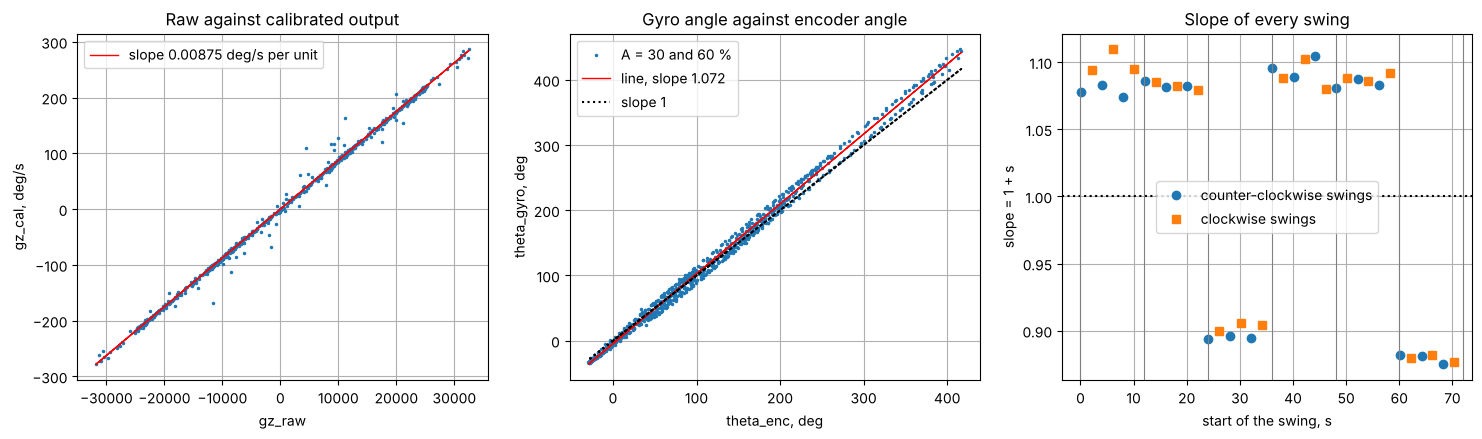

In [10]:
# 1. sign
ok = ~np.isnan(w_enc)
print(f'correlation of the gyro rate and the encoder rate: {np.corrcoef(turn.gz[ok], w_enc[ok])[0, 1]:.3f}')

# 2. raw -> deg/s
same = (np.abs(turn.gz_cal - 8.75 * turn.gz_raw) < 1).values[~sat]
print(f'raw -> deg/s: {k_raw:.5f} deg/s per raw unit ({1000 * k_raw:.2f} mdeg/s); gz_cal = 8.75 * gz_raw exactly in {same.sum()} of {len(same)} rows')

# 3. scale-factor error: a line fit of theta_gyro against theta_enc for every swing
u = turn.u.values
change = np.where(np.diff(np.sign(u)) != 0)[0] + 1        # rows where the motor command changes its sign
starts = np.concatenate([[0], change]); ends = np.concatenate([change, [len(tt)]])
swings = []                                                # start time, direction (+1 CCW, -1 CW), slope
for a, b in zip(starts, ends):
    if u[a] == 0 or b - a < 8:                             # rest or a too short piece
        continue
    part = np.arange(a, b)[tt[a:b] - tt[a] > 0.3]          # skip the first 0.3 s: the robot still turns the old way
    slope = np.polyfit(theta_enc[part], theta_gyro[part], 1)[0]
    swings.append([tt[a], np.sign(u[a]), slope])
swings = np.array(swings)

def s_of(t1, t2):
    # mean s in % of the swings that start between t1 and t2: counter-clockwise and clockwise
    m = (swings[:, 0] >= t1 - 0.2) & (swings[:, 0] < t2 - 0.2)
    return 100 * (swings[m & (swings[:, 1] > 0), 2].mean() - 1), 100 * (swings[m & (swings[:, 1] < 0), 2].mean() - 1)

for i, name in enumerate(names[:6]):
    a, b = s_of(12 * i, 12 * i + 12)
    print(f'{name:9s} s = {a:+6.1f} % CCW, {b:+6.1f} % CW')
slow_sw = (swings[:, 0] < 23.8) | ((swings[:, 0] > 35.8) & (swings[:, 0] < 59.8))    # amplitudes 30 and 60 %
s_ccw = 100 * (swings[slow_sw & (swings[:, 1] > 0), 2].mean() - 1)
s_cw = 100 * (swings[slow_sw & (swings[:, 1] < 0), 2].mean() - 1)
print(f'amplitudes 30 and 60 % together: s = {s_ccw:+.1f} % CCW, {s_cw:+.1f} % CW')
s = (s_ccw + s_cw) / 200

slow = (tt < 24) | ((tt > 36) & (tt < 60))
fit = np.polyfit(theta_enc[slow], theta_gyro[slow], 1)
print(f'one line through all points of 30 and 60 %: slope {fit[0]:.3f}')

fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
axs[0].plot(turn.gz_raw[~sat], turn.gz_cal[~sat] / 1000, '.', ms=3)
axs[0].plot(turn.gz_raw[~sat], k_raw * turn.gz_raw[~sat], 'r', lw=1, label=f'slope {k_raw:.5f} deg/s per unit')
axs[0].set_xlabel('gz_raw'); axs[0].set_ylabel('gz_cal, deg/s'); axs[0].set_title('Raw against calibrated output'); axs[0].legend()
axs[1].plot(theta_enc[slow], theta_gyro[slow], '.', ms=3, label='A = 30 and 60 %')
axs[1].plot(theta_enc[slow], np.polyval(fit, theta_enc[slow]), 'r', lw=1, label=f'line, slope {fit[0]:.3f}')
axs[1].plot(theta_enc[slow], theta_enc[slow], 'k:', label='slope 1')
axs[1].set_xlabel('theta_enc, deg'); axs[1].set_ylabel('theta_gyro, deg'); axs[1].set_title('Gyro angle against encoder angle'); axs[1].legend()
ccw = swings[:, 1] > 0
axs[2].plot(swings[ccw, 0], swings[ccw, 2], 'o', label='counter-clockwise swings')
axs[2].plot(swings[~ccw, 0], swings[~ccw, 2], 's', label='clockwise swings')
axs[2].axhline(1, color='k', ls=':')
for i in range(7):
    axs[2].axvline(12 * i, color='gray', lw=0.8)
axs[2].set_xlabel('start of the swing, s'); axs[2].set_ylabel('slope = 1 + s'); axs[2].set_title('Slope of every swing'); axs[2].legend()
for ax in axs: ax.grid(True)
plt.show()

1. Sign: the gyro rate and the encoder rate go together (correlation 0.98), so positive `gz` is counter-clockwise, the same as $\theta_{enc}$.
2. Raw → deg/s: `gz_cal` = 8.75 · `gz_raw` in mdeg/s, that is 0.00875 deg/s per raw unit. The points off the line are rows where `read()` and `readRawData()` returned two different samples. There is no offset between them: I did not call `calibrate()`, so `read()` has the same offset as the raw data.
3. At 30 and 60 % the slopes of the swings are between 1.07 and 1.11: $s$ = +8.5 % counter-clockwise and +9.0 % clockwise. The gyro shows about 9 % more rotation than the encoders, almost the same in both directions.
4. Below the limit $s$ does not depend on the speed: sin 30, sin 60, rect 30 and rect 60 all give 8-10 %. At 150 % the slope falls to 0.90 (sin) and 0.88 (rect), but this is saturation and not the scale factor.

$\theta_{enc}$ depends on r/L, so a part of these 9 % can be my r or L and not the gyro: with r = 4.2 cm from `Gyro_demo.qrs` the same data give $s$ of about -3 %.

## Slip check and my calibration on the rotation run

The README asks for a tape mark and a protractor. I had only a tape measure, so before and after the run I measured the distance from a wall to two points of the robot: the inner edges of the left and the right wheel, 16.6 cm apart. Before the run both were 39 cm from the wall. After the run the left one was 23 cm and the right one 19 cm from the wall. The angle is asin(difference / 16.6): the difference of the two distances is the side opposite the angle, and the 16.6 cm between the two points is the hypotenuse.

In [11]:
W = 16.6                         # cm between the two points on the robot (inner edges of the wheels)
before = [39, 39]                # cm from the wall to the left and to the right point
after = [23, 19]
tape = np.degrees(np.arcsin(((after[1] - after[0]) - (before[1] - before[0])) / W))   # + is counter-clockwise

b0_last = calibrate_gyro(static[static.t >= 170])          # my calibration on the last 10 s before the run
theta_mine = integrate(turn.gz - b0_last, turn.t)
still = turn[turn.t > turn.t.iloc[-1] - 2]                 # last 2 s, the robot stands again

print(f'tape                               {tape:6.1f} deg')
print(f'encoders                           {theta_enc[-1]:6.1f} deg')
print(f'gyro, b0 = {b0:.3f} (first 30 s)      {theta_gyro[-1]:6.1f} deg')
print(f'gyro, b0 = {b0_last:.3f} (last 10 s)       {theta_mine[-1]:6.1f} deg')
print(f'gyro at rest after the run: {still.gz.mean():.3f} deg/s')
print(f'rate left with b0 from the first 30 s: {still.gz.mean() - b0:+.3f} deg/s = {60 * (still.gz.mean() - b0):+.1f} deg/min')
print(f'rate left with my b0 from the last 10 s: {still.gz.mean() - b0_last:+.3f} deg/s = {60 * (still.gz.mean() - b0_last):+.1f} deg/min')

tape                                -13.9 deg
encoders                            -16.8 deg
gyro, b0 = 1.053 (first 30 s)       -14.1 deg
gyro, b0 = 0.953 (last 10 s)         -6.6 deg
gyro at rest after the run: 0.924 deg/s
rate left with b0 from the first 30 s: -0.129 deg/s = -7.8 deg/min
rate left with my b0 from the last 10 s: -0.029 deg/s = -1.7 deg/min


By the tape the robot stopped 13.9° clockwise from its start heading (about ±3°, because I read the tape to 1 cm). The encoders show -16.8°, the gyro -14.1° with $b_0$ from the first 30 s and -6.6° with my calibration on the last 10 s before the run ($b_0$ = 0.953).

The two gyro numbers differ only by the offset: 0.1 deg/s · 75 s = 7.5°. In the last 2 s the robot stands still and the gyro shows 0.924 deg/s, so during the run the offset was about 0.95 and not 1.05: my calibration leaves -0.03 deg/s (-1.7 deg/min) and the 3-min-old $b_0$ leaves -0.13 deg/s (-7.8 deg/min). So the fresh $b_0$ is the right one, and with it the gyro ends 7° from the tape and the encoders 3°.

A likely reason for these 7° is saturation: a quarter of the samples were at the limit, and if the robot turns a little faster one way, the clipped gyro loses more angle that way. The mark checks only the end of the run, so it cannot show which sensor is closer on the slow parts.

## Simulated gyro

`gyro_sim` is the model from the README with my numbers: scale factor, offset, drift and noise, then the limit and the resolution. As the true rate I give it the encoder rate of my rotation run.

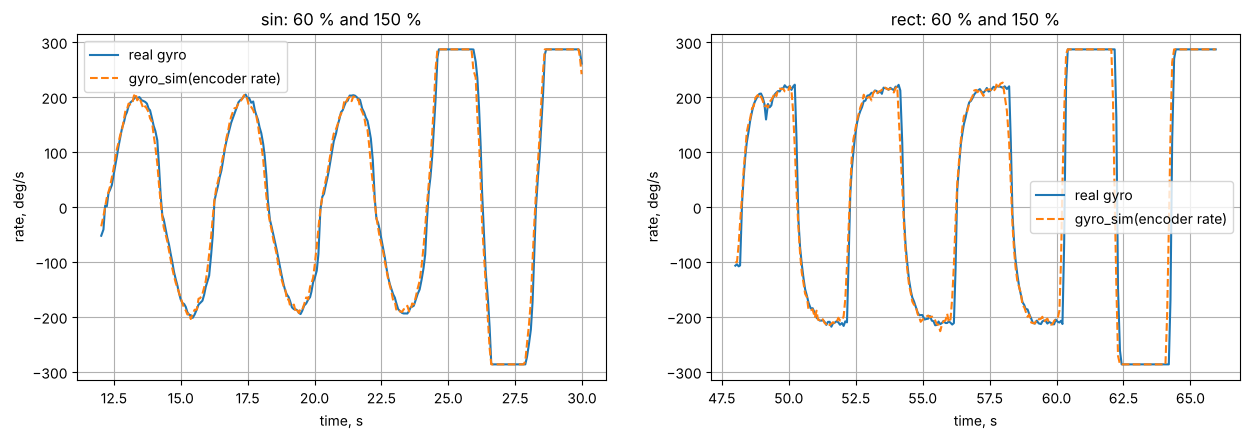

at rest: real mean 1.003, std 0.079; simulated mean 0.996, std 0.086 deg/s


In [12]:
w_max, w_min = turn.gz.max(), turn.gz.min()      # limits, deg/s
delta = step * k_raw                             # resolution, deg/s

def gyro_sim(omega_true, t):
    # model from the README with my parameters; omega_true in deg/s, t in s from the start of the log
    w = (1 + s) * omega_true + b0 + d * t + np.random.normal(0, sigma, len(t))
    w = np.clip(w, w_min, w_max)                 # saturation
    return np.round(w / delta) * delta           # resolution

np.random.seed(1)
gz_sim = gyro_sim(np.nan_to_num(w_enc), tt + 180)    # true rate = encoder rate; the run starts 180 s after the log start

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (a, b) in zip(axs, [(12, 30), (48, 66)]):
    m = (tt > a) & (tt < b)
    ax.plot(tt[m], turn.gz[m], label='real gyro')
    ax.plot(tt[m], gz_sim[m], '--', label='gyro_sim(encoder rate)')
    ax.set_xlabel('time, s'); ax.set_ylabel('rate, deg/s'); ax.grid(True); ax.legend()
axs[0].set_title('sin: 60 % and 150 %'); axs[1].set_title('rect: 60 % and 150 %')
plt.show()

rest_sim = gyro_sim(np.zeros(len(static)), static.t.values)
print(f'at rest: real mean {static.gz.mean():.3f}, std {static.gz.std():.3f}; simulated mean {rest_sim.mean():.3f}, std {rest_sim.std():.3f} deg/s')

The simulated gyro follows the real one on the slow parts and is cut at the same limit on the fast parts. At rest it gives the mean 0.996 and the std 0.086 deg/s against the real 1.003 and 0.079. Its std is a little bigger, because my $\sigma$ already has a part of the drift in it and the model adds the drift once more.

## Parameter table

| Parameter | Symbol | Value | Unit | Method |
|---|---|---|---|---|
| Offset (bias) | $b_0$ | 1.053 ± 0.003 | deg/s | static mean, T = 30 s |
| Bias drift | $d$ | -0.039 | deg/s/min | 30-s window means |
| Heading drift, uncorrected | | 60.2 | deg/min | slope of θ(t) |
| Measurement range | ±$\omega_{max}$ | +286.7 / -286.4 | deg/s | saturation test at ±100 % power |
| Resolution | $\Delta$ | 0.00875 | deg/s | quantisation step, 1 raw unit |
| Noise std | $\sigma$ | 0.079 | deg/s | static, 3 min |
| Raw → deg/s factor | | 0.00875 | deg/s per unit | `gz_cal` / `gz_raw` |
| Scale-factor error CCW / CW | $s$ | +8.5 / +9.0 | % | gyro vs. encoder angle, 30 and 60 % |
| Positive rotation direction | | CCW | — | §6 |

## Short analysis

Without calibration the offset dominates at any time: 1.05 deg/s gives about 11° after 10 s, 62° after 1 min and 180° after 3 min, even if the robot does not move.

With $b_0$ subtracted the next source at rest is the drift of the offset: it leaves -1.3° after 1 min and -9.1° after 3 min and grows faster with time. The noise is small: 0.079 deg/s at 22 samples per second gives about 0.2° after 3 min ($\sigma\sqrt{\Delta t \cdot t}$).

When the robot turns, the scale factor works from the first seconds: 9 % is 8° for every 90° of turning, if it is the gyro and not my r/L. So after 10 s of driving with turns it is the largest error, and after 1-3 min it is of the same size as the offset drift, depending on how much the robot turned. Saturation is the worst: above 286 deg/s the gyro lost up to 95° in one swing, so the turn rate has to stay below the limit.

My calibration: the robot stands still for 10 s and $b_0$ is the median of these samples. 10 s because the $b_0(T)$ curve is flat from there, the median so that one bumped sample does not shift it. After it the heading error at rest is -1.8° in 1 min and about -10° in 3 min, because the offset keeps falling by 0.04 deg/s per minute. So it has to be done right before every run: with the calibration on the last 10 s before my rotation run the gyro at rest after the run is off by only -0.03 deg/s, with the 3-min-old $b_0$ by -0.13 deg/s.